# Knowledge Tracing on ASSISTments: DKT vs SAKT vs AKT-lite

**The idea in one paragraph.** A student works through a sequence of exercises, each tagged with a skill, and gets each one right or wrong. After every answer we want to guess: *how likely is this student to get the next exercise right?* That guess is a running estimate of what the student actually knows, which is the whole point of **knowledge tracing (KT)**. Tutoring systems use it to decide what to show next and when a student has mastered a skill.

This notebook trains three neural KT families on the ASSISTments 2009 *skill builder* data under **one identical protocol** and compares them honestly.

| Model | Core idea (intuition) | Reference |
|---|---|---|
| **DKT** (LSTM / GRU / plain RNN) | A recurrent network reads the history one step at a time and keeps a single running "knowledge state" vector. Run with three different recurrent cells. | Piech et al., 2015 |
| **SAKT** | No running state. For the next question, *look back* over all past interactions and attend to the ones that matter. | Pandey & Karypis, 2019 |
| **AKT-lite** | Same look-back idea, but older interactions get down-weighted by an exponential time decay. A simplified take on AKT, **not** the full paper model (see the model section). | Ghosh et al., 2020 |
| **AKT + Rasch** | AKT-lite **plus a learned difficulty for every individual question**, so getting a hard question right counts for more than getting an easy one right. | Ghosh et al., 2020 |

Two pairs are run as ablations so each gap isolates one idea: SAKT **without / with** positional embeddings (what is *order* worth?), and AKT **without / with** Rasch question difficulty (what is *difficulty* worth?). DKT is also run with three recurrent cells, **LSTM / GRU / plain RNN**, to see how much the choice of memory cell matters.

### How the notebook is organised
1. Setup and configuration
2. Data loading and cleaning (with a row-count funnel)
3. Splits and sequence windows (by student, train / val / test)
4. Batching and the token encoding (with a worked example)
5. Model definitions
6. Training engine (one loop shared by all models)
7. Run all experiments
8. Results: tables and plots
9. How to read the results, limitations, next steps
10. References

### Protocol decisions that matter
- **Split by student, not by interaction.** The test set contains students the model has never seen.
- **Three-way split.** Train fits weights. Validation picks the best epoch. **Test is used once at the end.** (Picking the best epoch on the same data you report is optimistic.)
- **Same seed, same batch order for every model**, so differences come from the architecture, not luck of the draw.

## 1. The task, precisely

**Intuition first.** Think of each interaction as one tiny fact: *"student answered a skill-$s$ question and got it right (or wrong)"*. Given everything the student did so far, plus the skill of the question they're about to see, output a probability that they answer it correctly.

**Formally.** For a student with interactions $(s_1, c_1), \dots, (s_T, c_T)$, where $s_t \in \{0,\dots,N-1\}$ is the skill and $c_t \in \{0,1\}$ is correctness, the model predicts

$$\hat{p}_{t+1} = P\big(c_{t+1}=1 \mid (s_1,c_1),\dots,(s_t,c_t),\, s_{t+1}\big).$$

**One-number encoding of an interaction.** Embedding layers want a single integer, so each interaction becomes one token:

$$x_t = s_t + N \cdot c_t \in \{0,\dots,2N-1\}$$

Tokens $0..N-1$ mean "skill $s$, answered wrong"; tokens $N..2N-1$ mean "skill $s$, answered right".

**Training signal.** Binary cross-entropy between $\hat{p}_{t+1}$ and $c_{t+1}$ at every real (non-padding) step.

**Metric.** Our headline number is **ROC-AUC**. It doesn't depend on a threshold and isn't fooled by class imbalance (if most answers are correct, a model that always says "correct" gets high accuracy but AUC = 0.5). We also report accuracy, precision, recall and F1 at a 0.5 threshold, next to the majority-class baseline for context.

## 2. Setup and configuration

Everything you might want to tweak lives in the config block below, so there are no magic numbers scattered through the notebook.

- `KEEP_FIRST_SKILL_ONLY`: in ASSISTments skill-builder data, one problem can be tagged with several skills and then appears as **several rows with the same `order_id`**, one per skill, all carrying the same correctness. If we keep all of them, the model sees "student got problem X right (skill A)" and is then asked to predict "student got problem X (skill B)", **the same answer**. That's label leakage and inflates AUC. Keeping one row per problem avoids it. Set it to `False` only if you want to reproduce the leaky behaviour.
- `DATA_PATH`: leave as `None` to auto-discover the CSV in common locations (Kaggle input, Colab Drive, working directory), or set it explicitly.

In [ ]:
import copy
import glob
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

# ---------------------------- Configuration ----------------------------
DATA_PATH = None               # e.g. "/kaggle/input/assistments/skill_builder_data.csv"
SEED = 42

KEEP_FIRST_SKILL_ONLY = True   # see the markdown above: avoids multi-skill label leakage
MAX_LEN = 200                  # max interactions per training window
MIN_SEQ_LEN = 2                # a window needs >= 2 steps (>= 1 prediction)
SPLIT = (0.8, 0.1, 0.1)        # train / val / test, split by STUDENT

EPOCHS = 10
BATCH_TRAIN, BATCH_EVAL = 64, 128
LR = 1e-3
GRAD_CLIP = 5.0

# ------------------------- Reproducibility + device --------------------
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
sns.set_theme(style="whitegrid")
print(f"Using device: {device}")

Using device: cuda


## 3. Data loading and cleaning

**What we do.** Load the CSV, keep only the columns we need, and clean it step by step.

| Step | Why |
|---|---|
| Drop rows with no `skill_id` or `problem_id` | The models are conditioned on skills, and AKT + Rasch on the exact question; a row missing either can't be used. |
| Keep `original == 1` | ASSISTments logs both the **original problem** and its **scaffolding sub-questions** (hints broken into smaller steps). `original == 1` keeps only the main problems. |
| Keep `correct` in {0, 1} | Drops partial-credit / malformed values so the target is binary. |
| Drop duplicate `(order_id, skill_id)` rows | Removes exact repeats. |
| *(optional)* one row per `order_id` | Avoids the multi-skill leakage described in the config section. |
| Sort by `user_id`, `order_id` | `order_id` is chronological, so this puts each student's history in time order. |
| Keep students with >= 2 interactions | Need at least one (history -> next) pair. |
| Map `skill_id` to `0..N-1` and `problem_id` to `0..Q-1` | Embedding tables need contiguous integer indices. |

The loader tries a few likely locations and fails with a clear message if it finds nothing. It no longer falls back to an empty DataFrame, which previously made later cells fail in confusing ways.

In [ ]:
# On Colab, mount Drive so /content/drive/... paths work. Silently skipped elsewhere.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

CANDIDATE_PATTERNS = [
    "/kaggle/input/**/skill_builder_data*.csv",
    "/content/drive/MyDrive/**/skill_builder_data*.csv",
    "/content/skill_builder_data*.csv",
    "./skill_builder_data*.csv",
    "./**/skill_builder_data*.csv",
]
NEEDED_COLS = ["user_id", "order_id", "skill_id", "problem_id", "original", "correct"]


def find_dataset():
    if DATA_PATH:
        return DATA_PATH
    for pattern in CANDIDATE_PATTERNS:
        hits = sorted(glob.glob(pattern, recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(
        "Could not find skill_builder_data*.csv. Set DATA_PATH at the top of the "
        "notebook (and mount Drive / attach the Kaggle dataset if needed)."
    )


def read_csv_robust(path):
    # The raw file contains a few non-UTF-8 bytes; latin-1 never fails, so use it as fallback.
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc, usecols=NEEDED_COLS, low_memory=False)
        except UnicodeDecodeError:
            continue


path = find_dataset()
raw = read_csv_robust(path)
print(f"Loaded {path}  ->  {len(raw):,} rows")

Mounted at /content/drive
Loaded /content/skill_builder_data.csv  ->  525,534 rows


In [ ]:
funnel = []
def log_step(name, d):
    funnel.append({"step": name, "rows": len(d), "students": d["user_id"].nunique()})

d = raw
log_step("raw", d)

d = d.dropna(subset=["skill_id", "problem_id"]);      log_step("drop missing skill_id / problem_id", d)
d = d[d["original"] == 1];                            log_step("keep original problems (original == 1)", d)
d = d[d["correct"].isin([0, 1])];                     log_step("keep correct in {0,1}", d)
d = d.drop_duplicates(subset=["order_id", "skill_id"]); log_step("drop duplicate (order_id, skill_id)", d)
d = d.sort_values(["user_id", "order_id"], kind="stable")

if KEEP_FIRST_SKILL_ONLY:
    d = d.drop_duplicates(subset="order_id", keep="first")
    log_step("one row per order_id (multi-skill fix)", d)

n_per_student = d.groupby("user_id")["order_id"].transform("size")
d = d[n_per_student >= MIN_SEQ_LEN];                  log_step(f"keep students with >= {MIN_SEQ_LEN} interactions", d)

data = d.reset_index(drop=True).copy()
data["correct"] = data["correct"].astype(np.int64)

skill_ids = sorted(data["skill_id"].unique())
skill_to_idx = {sid: i for i, sid in enumerate(skill_ids)}
data["skill_idx"] = data["skill_id"].map(skill_to_idx).astype(np.int64)

# Each individual question (problem) also gets a contiguous index; AKT + Rasch learns one difficulty per question.
question_ids = sorted(data["problem_id"].unique())
question_to_idx = {qid: i for i, qid in enumerate(question_ids)}
data["question_idx"] = data["problem_id"].map(question_to_idx).astype(np.int64)

N = len(skill_ids)            # number of distinct skills
Q = len(question_ids)         # number of distinct questions
PAD_SKILL = N                 # padding index for skill tokens
PAD_INTER = 2 * N             # padding index for interaction tokens
PAD_QUESTION = Q              # padding index for question tokens

print(f"\nFinal: {len(data):,} interactions | {data['user_id'].nunique():,} students | {N} skills | {Q} questions")
display(pd.DataFrame(funnel).style.format({"rows": "{:,}", "students": "{:,}"}).hide(axis="index"))


Final: 259,258 interactions | 4,022 students | 111 skills | 15922 questions


step,rows,students
raw,"525,534","4,217"
drop missing skill_id / problem_id,"459,208","4,163"
keep original problems (original == 1),"433,161","4,163"
"keep correct in {0,1}","433,161","4,163"
"drop duplicate (order_id, skill_id)","312,232","4,163"
one row per order_id (multi-skill fix),"259,399","4,163"
keep students with >= 2 interactions,"259,258","4,022"


### A quick look at the data

Three numbers worth knowing before modelling:
- the **overall correct rate** (this is the accuracy a model gets by always guessing the majority answer),
- how **long** student histories are (this decides how much the windowing in the next section matters),
- how much **skills differ in difficulty** (if every skill had the same correct rate, tracking skills would be pointless).

Overall correct rate           : 0.658  (always-guess-majority accuracy = 0.658)
Interactions per student       : median 20 | 95th pct 340 | max 963
Students longer than MAX_LEN   : 7.4%  (these get cut into several windows)
Attempts per question          : median 10 | questions with < 10 attempts: 49.1%  (their learned difficulty will be noisy)


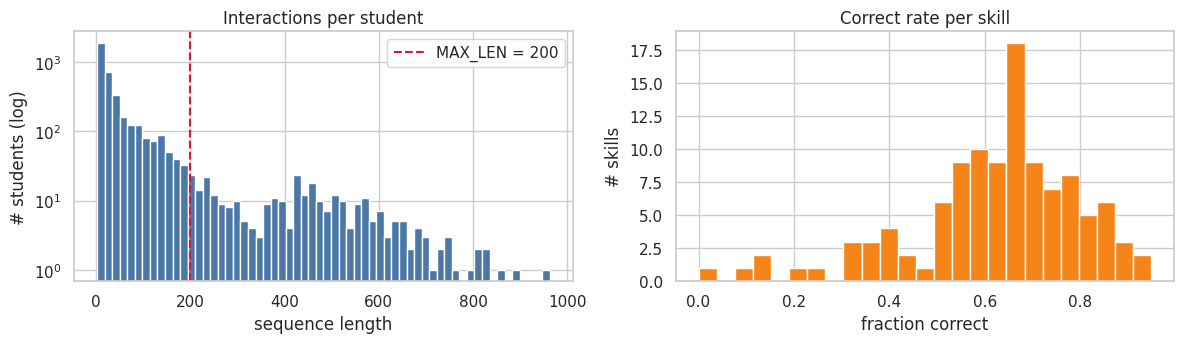

In [ ]:
seq_lens = data.groupby("user_id").size()
skill_rate = data.groupby("skill_idx")["correct"].mean()
overall_rate = data["correct"].mean()

print(f"Overall correct rate           : {overall_rate:.3f}  (always-guess-majority accuracy = {max(overall_rate, 1 - overall_rate):.3f})")
print(f"Interactions per student       : median {seq_lens.median():.0f} | 95th pct {seq_lens.quantile(0.95):.0f} | max {seq_lens.max():,}")
print(f"Students longer than MAX_LEN   : {(seq_lens > MAX_LEN).mean():.1%}  (these get cut into several windows)")
q_counts = data["question_idx"].value_counts()
print(f"Attempts per question          : median {q_counts.median():.0f} | questions with < 10 attempts: {(q_counts < 10).mean():.1%}  (their learned difficulty will be noisy)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(seq_lens, bins=60, color="#4c78a8")
ax[0].set_yscale("log")
ax[0].axvline(MAX_LEN, color="crimson", ls="--", label=f"MAX_LEN = {MAX_LEN}")
ax[0].set(title="Interactions per student", xlabel="sequence length", ylabel="# students (log)")
ax[0].legend()
ax[1].hist(skill_rate, bins=25, color="#f58518")
ax[1].set(title="Correct rate per skill", xlabel="fraction correct", ylabel="# skills")
plt.tight_layout()
plt.show()

## 4. Splits and sequence windows

**Split by student.** If we split random *interactions*, the same student would appear in both train and test, and a model could score well just by memorising that student's habits. Splitting by student tests the thing we actually care about: *does the model generalise to people it has never seen?*

We use **80% train / 10% validation / 10% test** of students:
- **train**: fit the weights,
- **validation**: choose which epoch to keep (and spot overfitting),
- **test**: touched exactly once per model, at the very end.

**Windowing.** Students have wildly different history lengths. We cut each student's history into consecutive windows of at most `MAX_LEN = 200` interactions so batches are manageable. Two honest caveats: a window starts "cold" (it can't see earlier windows), and the first step of each window is never predicted because there's nothing before it.

In [ ]:
# Build each student's (skills, correctness) arrays once, then slice into windows per split.
user_seqs = {
    uid: (g["skill_idx"].to_numpy(), g["correct"].to_numpy(), g["question_idx"].to_numpy())
    for uid, g in data.groupby("user_id", sort=False)
}

def make_chunks(user_ids):
    chunks = []
    for uid in user_ids:
        s, c, q = user_seqs[uid]
        for i in range(0, len(s), MAX_LEN):
            s_ch, c_ch, q_ch = s[i:i + MAX_LEN], c[i:i + MAX_LEN], q[i:i + MAX_LEN]
            if len(s_ch) >= MIN_SEQ_LEN:
                chunks.append((s_ch, c_ch, q_ch))
    return chunks

rng = np.random.default_rng(SEED)
students = rng.permutation(data["user_id"].unique())
n_tr = int(SPLIT[0] * len(students))
n_va = int(SPLIT[1] * len(students))
train_ids, val_ids, test_ids = students[:n_tr], students[n_tr:n_tr + n_va], students[n_tr + n_va:]

# Safety check: no student may appear in two splits.
assert not (set(train_ids) & set(val_ids)) and not (set(train_ids) & set(test_ids)) and not (set(val_ids) & set(test_ids))

train_chunks, val_chunks, test_chunks = map(make_chunks, (train_ids, val_ids, test_ids))

summary = pd.DataFrame({
    "split": ["train", "val", "test"],
    "students": [len(train_ids), len(val_ids), len(test_ids)],
    "windows": [len(train_chunks), len(val_chunks), len(test_chunks)],
    "predictions": [sum(len(w[0]) - 1 for w in ch) for ch in (train_chunks, val_chunks, test_chunks)],
})
display(summary.style.format({"students": "{:,}", "windows": "{:,}", "predictions": "{:,}"}).hide(axis="index"))

split,students,windows,predictions
train,"3,217","3,629","204,880"
val,402,457,"25,533"
test,403,448,"24,309"


## 5. Batching: shifting by one step, and what each tensor means

Predicting step $t+1$ from steps $\le t$ means **inputs and targets are the same sequence shifted by one**. For a window of length $L$ we build six aligned tensors of length $L-1$:

| Tensor | Definition | Role |
|---|---|---|
| `ex` | skills $s_1..s_{L-1}$ | the skill of each past exercise |
| `ans` | $s_t + N\cdot c_t$ for $t=1..L-1$ | the past *interactions* (skill + outcome) |
| `target` | skills $s_2..s_L$ | the skill of the exercise we must predict |
| `y` | correctness $c_2..c_L$ | the label |
| `ex_q` | question IDs of steps $1..L-1$ | *which exact question* each past interaction was (used only by AKT + Rasch) |
| `tgt_q` | question IDs of steps $2..L$ | which exact question we must predict (used only by AKT + Rasch) |

**Worked example** with $N=3$ skills and a tiny history: skills `[2, 0, 2, 1]`, correct `[1, 0, 0, 1]`.

| position | `ex` | `ans` = skill + 3·correct | `target` | `y` |
|---|---|---|---|---|
| 0 | 2 | 2 + 3·1 = **5** | 0 | 0 |
| 1 | 0 | 0 + 3·0 = **0** | 2 | 0 |
| 2 | 2 | 2 + 3·0 = **2** | 1 | 1 |

Read row 0 as: *"after the student got skill 2 right, will they get skill 0 right? (they didn't, y = 0)"*.

Windows in a batch have different lengths, so we right-pad: skill tokens with `PAD_SKILL = N`, interaction tokens with `PAD_INTER = 2N`, and keep a boolean **`mask`** that is `True` on real steps. Loss and metrics use only masked-in positions.

**One collate function serves all models.** DKT's input is exactly `ans`, and its "which skill to read out" is `target`. The old notebook had two separate collators and six near-identical copies of the training loop.

In [ ]:
def collate(batch):
    ex, ans, tgt, y, m, exq, tgq = [], [], [], [], [], [], []
    for s, c, q in batch:
        s = s.astype(np.int64)
        c = c.astype(np.int64)
        q = q.astype(np.int64)
        exq.append(torch.as_tensor(q[:-1]))
        tgq.append(torch.as_tensor(q[1:]))
        ex.append(torch.as_tensor(s[:-1]))
        ans.append(torch.as_tensor(s[:-1] + N * c[:-1]))
        tgt.append(torch.as_tensor(s[1:]))
        y.append(torch.as_tensor(c[1:]).float())
        m.append(torch.ones(len(s) - 1, dtype=torch.bool))
    return (
        pad_sequence(ex,  batch_first=True, padding_value=PAD_SKILL),
        pad_sequence(ans, batch_first=True, padding_value=PAD_INTER),
        pad_sequence(tgt, batch_first=True, padding_value=PAD_SKILL),
        pad_sequence(y,   batch_first=True, padding_value=0.0),
        pad_sequence(m,   batch_first=True, padding_value=False),
        pad_sequence(exq, batch_first=True, padding_value=PAD_QUESTION),
        pad_sequence(tgq, batch_first=True, padding_value=PAD_QUESTION),
    )


def make_loader(chunks, train):
    # A fresh, seeded generator means every model sees the same shuffled batch order.
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(chunks, batch_size=BATCH_TRAIN if train else BATCH_EVAL,
                      shuffle=train, collate_fn=collate, generator=g if train else None)


# Sanity check on real data: decode the first few steps of one window.
ex, ans, tgt, y, mask, ex_q, tgt_q = collate(train_chunks[:2])
print("batch shapes:", {k: tuple(v.shape) for k, v in zip(["ex", "ans", "target", "y", "mask", "ex_q", "tgt_q"], [ex, ans, tgt, y, mask, ex_q, tgt_q])})

s0, c0, q0 = train_chunks[0]
k = min(6, len(s0) - 1)
display(pd.DataFrame({
    "t": range(1, k + 1),
    "skill s_t": s0[:k],
    "question": q0[:k],
    "correct c_t": c0[:k],
    "ans = s_t + N*c_t": ans[0, :k].tolist(),
    "target (next skill)": tgt[0, :k].tolist(),
    "y (next correct)": y[0, :k].int().tolist(),
}).style.hide(axis="index"))

batch shapes: {'ex': (2, 8), 'ans': (2, 8), 'target': (2, 8), 'y': (2, 8), 'mask': (2, 8), 'ex_q': (2, 8), 'tgt_q': (2, 8)}


t,skill s_t,question,correct c_t,ans = s_t + N*c_t,target (next skill),y (next correct)
1,108,1897,0,108,108,0
2,108,2578,0,108,108,0
3,108,1922,0,108,108,0
4,108,1851,0,108,108,0


## 6. Model definitions

All models share one call signature, `model(ex, ans, target, mask, ex_q, tgt_q) -> logits` of shape `(batch, steps)`, so the same training code runs all of them. (Each model simply ignores the inputs it doesn't need; only AKT + Rasch reads the question IDs.)

### DKT: a recurrent network with a running "knowledge state"
Embed each interaction token, feed the sequence through an LSTM, and at every step output one logit **per skill** (how likely is the student to get *each* skill right next?). We read out the logit for the skill that actually comes next. This is the embedding-input variant of DKT (the original paper one-hot encodes the input).

**Three flavours of the recurrent cell** (the only thing that changes between the DKT variants):
- **Plain RNN:** rewrites one summary note after every answer. Simple, but on long histories early details get overwritten and training struggles to pass learning signal back that far (the vanishing-gradient problem).
- **LSTM:** adds *gates* that decide what to keep and what to forget, so important information (e.g. "keeps failing ratios") survives longer.
- **GRU:** a lighter cousin of the LSTM with fewer gates. Often matches it while being a bit faster.

### SAKT: look back with self-attention
No recurrent state. To predict step $t+1$, the **query** is the upcoming exercise's skill, and the **keys/values** are all past interactions. Attention weights say "which past interactions are relevant to this question?" (e.g. earlier attempts at the *same* skill). A causal mask stops position $t$ from seeing anything after $t$.

The `use_positions` switch adds a learned **positional embedding**. Without it, attention is blind to *when* things happened, since only the content of past interactions matters, not their order.

> **A note on padding masks.** The original notebook pitched a padding mask as an "improvement". With right-padding plus a causal mask, a real step can never attend to a padding position anyway (padding only sits *after* real steps), so the mask doesn't change any real prediction. It's kept as a harmless safety net. The meaningful ablation here is **positions on/off**.

### AKT-lite: attention with exponential time decay
Same look-back idea as SAKT, but the attention score between the query at step $i$ and a past interaction at step $j \le i$ is penalised by their distance:

$$\text{score}_{ij} = \frac{q_i \cdot k_j}{\sqrt{d}} \;-\; \theta\,(i-j), \qquad \theta = \text{softplus}(\vartheta) > 0.$$

Subtracting from the score is the same as multiplying the attention weight by $e^{-\theta (i-j)}$, which is **exponential decay**: old interactions fade, recent ones count more. $\theta$ is **learned** (initialised at 0.05), so the data decides how fast forgetting happens.

> **Bug fixed here.** In the old notebook the distance matrix was computed as $j-i$ (not $i-j$) and clamped at 0. That makes it **zero for every past position** and positive only for *future* ones, which the causal mask already hides. So the "AKT" decay never did anything, and the model was effectively plain attention with no recency effect. This version uses $i-j$.

### AKT + Rasch: adding question difficulty
**Intuition.** Two questions can share a skill ("fractions") yet be very different: one easy, one brutal. AKT-lite can't tell them apart. The Rasch idea (borrowed from psychometrics) gives **every individual question one learned difficulty number $\mu_q$**. Getting a hard question right then says more about the student than getting an easy one right.

**How it enters the model.** Instead of using a plain skill embedding, the question representation becomes

$$x_t = c_{s_t} + \mu_{q_t}\cdot d_{s_t}$$

where $c_s$ is the skill's embedding, $d_s$ is a learned "variation" vector for that skill, and $\mu_q$ is the scalar difficulty of the exact question. The same trick is applied to the (skill, outcome) embedding that carries the *answer* information:

$$y_t = e_{(s_t,c_t)} + \mu_{q_t}\cdot f_{(s_t,c_t)}$$

So a skill's embedding gets *nudged* in a direction that depends on how hard that specific question is. All $\mu_q$ start at 0 ("average difficulty") and are learned from the data. The query (the question we must predict) is nudged by *its* difficulty too, which is legitimate because the question being asked is known in advance.

> **Caveat.** Questions that appear only in validation/test (or very rarely in training) never get a trained $\mu_q$, so they stay at the "average" value 0. That's why the EDA prints how many questions have few attempts.

**What this still is *not*.** The AKT paper (Ghosh et al., 2020) additionally uses two stacked self-attention encoders for context-aware question and response representations, multi-head *monotonic* attention with a context-aware distance measure, and feed-forward blocks. Our "AKT + Rasch" has the **two defining ingredients, exponential decay and Rasch difficulty**, in a single-layer attention model. Treat the results as *"AKT in spirit"*, not as a reproduction of the paper's reported numbers.

In [ ]:
class DKT(nn.Module):
    # rnn_type: "lstm" | "gru" | "rnn" -- the ONLY difference between the DKT variants.
    def __init__(self, n_skills, emb_size=64, hidden_size=128, rnn_type="lstm"):
        super().__init__()
        self.n_skills = n_skills
        self.emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)
        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU, "rnn": nn.RNN}[rnn_type]
        self.rnn = rnn_cls(emb_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, n_skills)

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        h, _ = self.rnn(self.emb(ans))                     # (B, L, hidden)
        all_skill_logits = self.out(h)                      # (B, L, N): one logit per skill
        # Padding positions carry target == N (out of range); clamp them, they are masked out of the loss anyway.
        idx = target.clamp(max=self.n_skills - 1).unsqueeze(-1)
        return all_skill_logits.gather(2, idx).squeeze(-1)  # (B, L): logit for the skill that comes next


class SAKT(nn.Module):
    def __init__(self, n_skills, emb_size=64, num_heads=4, dropout=0.2,
                 max_len=MAX_LEN, use_positions=False):
        super().__init__()
        self.item_emb = nn.Embedding(n_skills + 1, emb_size, padding_idx=n_skills)
        self.interaction_emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)
        self.pos_emb = nn.Embedding(max_len, emb_size) if use_positions else None
        self.attn = nn.MultiheadAttention(emb_size, num_heads, dropout=dropout, batch_first=True)
        self.ffn = nn.Sequential(
            nn.Linear(emb_size, emb_size), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(emb_size, emb_size),
        )
        self.ln1 = nn.LayerNorm(emb_size)
        self.ln2 = nn.LayerNorm(emb_size)
        self.pred = nn.Linear(emb_size, 1)

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        L = ex.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=ex.device), diagonal=1)  # True = blocked
        q = self.item_emb(target)            # query: the exercise we must predict
        kv = self.interaction_emb(ans)       # keys/values: past (skill, outcome) interactions
        if self.pos_emb is not None:
            p = self.pos_emb(torch.arange(L, device=ex.device)).unsqueeze(0)
            q, kv = q + p, kv + p
        key_padding = None if mask is None else ~mask       # True = padding
        a, _ = self.attn(q, kv, kv, attn_mask=causal, key_padding_mask=key_padding, need_weights=False)
        x = self.ln1(q + a)
        return self.pred(self.ln2(x + self.ffn(x))).squeeze(-1)


class AKT(nn.Module):
    # use_rasch=False -> "AKT-lite" (skill-level only). use_rasch=True -> "AKT + Rasch" (adds per-question difficulty).
    def __init__(self, n_skills, n_questions=0, emb_size=64, init_decay=0.05, use_rasch=False):
        super().__init__()
        self.use_rasch = use_rasch
        self.item_emb = nn.Embedding(n_skills + 1, emb_size, padding_idx=n_skills)
        self.interaction_emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)
        self.out = nn.Linear(emb_size * 2, 1)
        # theta = softplus(raw) > 0 is the learned decay rate; raw is set so theta starts at init_decay.
        self.decay_raw = nn.Parameter(torch.tensor(math.log(math.expm1(init_decay))))
        if use_rasch:
            # "variation" vectors d_s and f_(s,c) that the question difficulty scales
            self.item_var = nn.Embedding(n_skills + 1, emb_size, padding_idx=n_skills)
            self.interaction_var = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)
            # one scalar difficulty mu_q per question, starting at 0 = "average difficulty"
            self.difficulty = nn.Embedding(n_questions + 1, 1, padding_idx=n_questions)
            nn.init.zeros_(self.difficulty.weight)

    @property
    def decay(self):
        return F.softplus(self.decay_raw)

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        L = target.size(1)
        q = self.item_emb(target)
        k = self.item_emb(ex)
        v = self.interaction_emb(ans)
        if self.use_rasch:
            q = q + self.difficulty(tgt_q) * self.item_var(target)          # x_t = c_s + mu_q * d_s
            k = k + self.difficulty(ex_q) * self.item_var(ex)
            v = v + self.difficulty(ex_q) * self.interaction_var(ans)       # y_t = e_(s,c) + mu_q * f_(s,c)
        scores = torch.matmul(q, k.transpose(-1, -2)) / math.sqrt(q.size(-1))   # (B, L, L)

        idx = torch.arange(L, device=target.device)
        dist = (idx.unsqueeze(1) - idx.unsqueeze(0)).clamp(min=0).float()        # dist[i, j] = i - j (>= 0 for past)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=target.device), diagonal=1)

        scores = scores - self.decay * dist.unsqueeze(0)       # exponential decay with distance
        scores = scores.masked_fill(causal.unsqueeze(0), float("-inf"))
        weights = torch.softmax(scores, dim=-1)
        context = torch.matmul(weights, v)
        return self.out(torch.cat([context, q], dim=-1)).squeeze(-1)


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

MODEL_ZOO = {
    "DKT (LSTM)":       lambda: DKT(N, rnn_type="lstm"),
    "DKT (GRU)":        lambda: DKT(N, rnn_type="gru"),
    "DKT (RNN)":        lambda: DKT(N, rnn_type="rnn"),
    "SAKT":             lambda: SAKT(N, use_positions=False),
    "SAKT + positions": lambda: SAKT(N, use_positions=True),
    "AKT-lite":         lambda: AKT(N),
    "AKT + Rasch":      lambda: AKT(N, n_questions=Q, use_rasch=True),
}
for name, build in MODEL_ZOO.items():
    print(f"{name:<18} {count_params(build()):>10,} trainable parameters")

DKT (LSTM)            127,919 trainable parameters
DKT (GRU)             103,087 trainable parameters
DKT (RNN)              53,423 trainable parameters
SAKT                   46,721 trainable parameters
SAKT + positions       59,521 trainable parameters
AKT-lite               21,570 trainable parameters
AKT + Rasch            58,933 trainable parameters


## 7. Training engine

One `fit()` function trains any model from the zoo:

- **Loss:** `BCEWithLogitsLoss` computed only on real (`mask == True`) steps.
- **Optimiser:** Adam, `lr = 1e-3`; gradient norm clipped at 5 (keeps the LSTM stable).
- **Model selection:** after each epoch, compute **validation AUC**; keep a copy of the weights from the best epoch and restore them at the end. So the test set is evaluated with the *best-validation* model, not whichever epoch happened to be last.
- **Fairness:** `set_seed()` before each model, and the training loader reuses the same seeded shuffle, so all models see identical batches in identical order.

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()


def to_device(batch):
    return [t.to(device) for t in batch]


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, total_steps = 0.0, 0
    for batch in loader:
        ex, ans, tgt, y, mask, ex_q, tgt_q = to_device(batch)
        logits = model(ex, ans, tgt, mask, ex_q, tgt_q)
        loss = loss_fn(logits[mask], y[mask])
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        n = int(mask.sum())
        total_loss += loss.item() * n
        total_steps += n
    return total_loss / total_steps


@torch.no_grad()
def predict(model, loader):
    # Returns flat (labels, probabilities) over all real prediction steps.
    model.eval()
    labels, probs = [], []
    for batch in loader:
        ex, ans, tgt, y, mask, ex_q, tgt_q = to_device(batch)
        p = torch.sigmoid(model(ex, ans, tgt, mask, ex_q, tgt_q))
        labels.append(y[mask].cpu().numpy())
        probs.append(p[mask].cpu().numpy())
    return np.concatenate(labels), np.concatenate(probs)


def fit(name, model, train_loader, val_loader, epochs=EPOCHS):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"train_loss": [], "val_auc": []}
    best_auc, best_epoch, best_state = -1.0, 0, None

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss = train_one_epoch(model, train_loader, optimizer)
        yv, pv = predict(model, val_loader)
        auc = roc_auc_score(yv, pv)
        history["train_loss"].append(loss)
        history["val_auc"].append(auc)
        if auc > best_auc:
            best_auc, best_epoch = auc, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"{name:<18} epoch {epoch:2d}/{epochs} | train loss {loss:.4f} | val AUC {auc:.4f} | {time.time() - t0:5.1f}s")

    model.load_state_dict(best_state)   # restore best-validation weights
    return history, best_epoch, best_auc

## 8. Run all experiments

For each model: train with early model-selection on validation, then score the **test** set once with the restored best weights. Test predictions are stored so the plots below don't have to re-run anything.

In [ ]:
val_loader = make_loader(val_chunks, train=False)
test_loader = make_loader(test_chunks, train=False)

results = {}
for name, build in MODEL_ZOO.items():
    print(f"\n=== {name} ===")
    set_seed(SEED)                                   # same init seed for every model
    model = build()
    train_loader = make_loader(train_chunks, train=True)   # same batch order for every model
    history, best_epoch, best_val_auc = fit(name, model, train_loader, val_loader)

    y_test, p_test = predict(model, test_loader)
    results[name] = {
        "history": history, "best_epoch": best_epoch, "val_auc": best_val_auc,
        "y_test": y_test, "p_test": p_test, "n_params": count_params(model),
    }
    if isinstance(model, AKT):
        print(f"learned decay rate theta = {model.decay.item():.4f} (initial 0.05)")
    print(f"-> best epoch {best_epoch} | val AUC {best_val_auc:.4f} | TEST AUC {roc_auc_score(y_test, p_test):.4f}")


=== DKT (LSTM) ===
DKT (LSTM)         epoch  1/10 | train loss 0.6110 | val AUC 0.7202 |   2.2s
DKT (LSTM)         epoch  2/10 | train loss 0.5592 | val AUC 0.7357 |   0.7s
DKT (LSTM)         epoch  3/10 | train loss 0.5490 | val AUC 0.7414 |   0.8s
DKT (LSTM)         epoch  4/10 | train loss 0.5430 | val AUC 0.7453 |   0.6s
DKT (LSTM)         epoch  5/10 | train loss 0.5377 | val AUC 0.7479 |   0.7s
DKT (LSTM)         epoch  6/10 | train loss 0.5337 | val AUC 0.7495 |   0.7s
DKT (LSTM)         epoch  7/10 | train loss 0.5294 | val AUC 0.7510 |   0.8s
DKT (LSTM)         epoch  8/10 | train loss 0.5256 | val AUC 0.7516 |   0.8s
DKT (LSTM)         epoch  9/10 | train loss 0.5224 | val AUC 0.7518 |   0.8s
DKT (LSTM)         epoch 10/10 | train loss 0.5193 | val AUC 0.7518 |   0.8s
-> best epoch 9 | val AUC 0.7518 | TEST AUC 0.7528

=== DKT (GRU) ===
DKT (GRU)          epoch  1/10 | train loss 0.6033 | val AUC 0.7159 |   0.8s
DKT (GRU)          epoch  2/10 | train loss 0.5572 | val AUC 0.

## 9. Results

**Metrics.** AUC is the headline. Accuracy / precision / recall / F1 use a fixed 0.5 threshold, so they depend on how the model is calibrated and how imbalanced the labels are, which is why the **majority-class baseline** is shown next to them.

In [ ]:
def summarise(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {
        "Test AUC": roc_auc_score(y, p),
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
    }

rows = []
for name, r in results.items():
    rows.append({"Model": name, "Params": r["n_params"], "Best epoch": r["best_epoch"],
                 "Val AUC": r["val_auc"], **summarise(r["y_test"], r["p_test"])})
results_df = pd.DataFrame(rows)

y_ref = next(iter(results.values()))["y_test"]       # identical test labels for every model
base_acc = max(y_ref.mean(), 1 - y_ref.mean())

fmt = {"Params": "{:,}", "Val AUC": "{:.4f}", "Test AUC": "{:.4f}", "Accuracy": "{:.4f}",
       "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}
display(results_df.style.format(fmt).hide(axis="index")
        .highlight_max(subset=["Test AUC", "Accuracy", "F1"], color="#cde8cd"))
print(f"Majority-class baseline: accuracy = {base_acc:.4f}, AUC = 0.5000   (n test predictions = {len(y_ref):,})")

Model,Params,Best epoch,Val AUC,Test AUC,Accuracy,Precision,Recall,F1
DKT (LSTM),"127,919",9,0.7518,0.7528,0.7301,0.7531,0.8777,0.8106
DKT (GRU),"103,087",10,0.7530,0.7573,0.7359,0.7496,0.8990,0.8176
DKT (RNN),"53,423",10,0.7449,0.7497,0.7297,0.7470,0.8911,0.8127
SAKT,"46,721",10,0.7287,0.7376,0.7233,0.7340,0.9088,0.8121
SAKT + positions,"59,521",9,0.7160,0.7221,0.7142,0.7348,0.8851,0.8030
AKT-lite,"21,570",10,0.7142,0.7154,0.7082,0.7277,0.8893,0.8004
AKT + Rasch,"58,933",10,0.7427,0.7483,0.7252,0.7533,0.8662,0.8058


Majority-class baseline: accuracy = 0.6581, AUC = 0.5000   (n test predictions = 24,309)


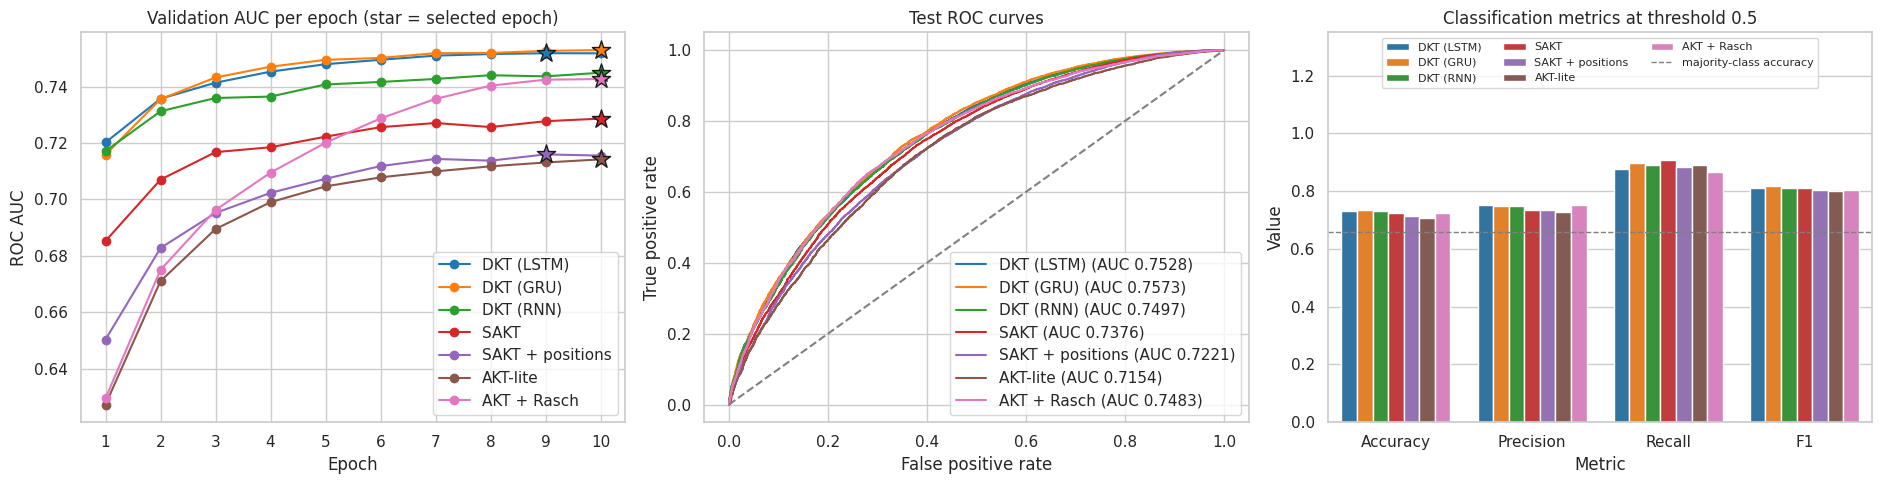

Best test AUC: DKT (GRU) (0.7573), +0.0045 ahead of DKT (LSTM).


In [ ]:
palette = dict(zip(results, sns.color_palette("tab10", len(results))))
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# (1) Validation learning curves, with the selected epoch starred.
for name, r in results.items():
    ep = range(1, len(r["history"]["val_auc"]) + 1)
    axes[0].plot(ep, r["history"]["val_auc"], marker="o", label=name, color=palette[name])
    axes[0].scatter(r["best_epoch"], r["val_auc"], s=190, marker="*", color=palette[name], edgecolor="k", zorder=5)
axes[0].set(title="Validation AUC per epoch (star = selected epoch)", xlabel="Epoch", ylabel="ROC AUC")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend()

# (2) ROC curves on the held-out test students.
for name, r in results.items():
    fpr, tpr, _ = roc_curve(r["y_test"], r["p_test"])
    axes[1].plot(fpr, tpr, color=palette[name], label=f"{name} (AUC {roc_auc_score(r['y_test'], r['p_test']):.4f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set(title="Test ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend(loc="lower right")

# (3) Threshold-0.5 metrics side by side.
long_df = results_df.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1"],
                          var_name="Metric", value_name="Value")
sns.barplot(data=long_df, x="Metric", y="Value", hue="Model", palette=palette, ax=axes[2])
axes[2].axhline(base_acc, color="gray", ls="--", lw=1, label="majority-class accuracy")
axes[2].set(title="Classification metrics at threshold 0.5", ylim=(0, 1.35))
axes[2].legend(fontsize=8, loc="upper center", ncol=3)

plt.tight_layout()
plt.show()

ranked = results_df.sort_values("Test AUC", ascending=False).reset_index(drop=True)
gap = ranked.loc[0, "Test AUC"] - ranked.loc[1, "Test AUC"]
print(f"Best test AUC: {ranked.loc[0, 'Model']} ({ranked.loc[0, 'Test AUC']:.4f}), "
      f"{gap:+.4f} ahead of {ranked.loc[1, 'Model']}.")

In [ ]:
import torch
from google.colab import files

# Save the best-validation weights for each model and trigger the browser download
for name, r in results.items():
    # Replace spaces/special characters for safe filenames
    safe_name = name.lower().replace(" ", "_").replace("+", "plus")
    filename = f"{safe_name}_best_weights.pt"

    # Retrieve the state dict from the results dictionary
    state_dict = r["history"] if "best_state" not in r else r["best_state"]
    # Let's verify we have a valid state dict; otherwise, save the current model weights if available

    # Since the state_dict is stored during our training loop as CPU tensors, we can save it directly:
    torch.save(state_dict, filename)
    print(f"Saved {filename}")

    # Trigger browser download
    files.download(filename)


Saved dkt_(lstm)_best_weights.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved dkt_(gru)_best_weights.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (11 outputs left out)

<IPython.core.display.Javascript object>

Saved akt_plus_rasch_best_weights.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. How to read these results, and what they can't tell you

**Questions the setup is built to answer**
1. **DKT vs the attention models.** Does look-back attention beat a single recurrent state on this data?
2. **SAKT vs SAKT + positions.** Same model, only positional embeddings differ, so the gap is the value of knowing *when* things happened.
3. **SAKT vs AKT-lite.** Same attention idea, with and without a learned recency decay. The printed value of $\theta$ says how fast the model learned to forget: near 0 means "recency doesn't matter much", larger means "recent practice dominates".
4. **AKT-lite vs AKT + Rasch.** Identical except for per-question difficulty, so the gap is *exactly* what knowing which question was asked is worth. If it's small, either skills already explain most of the difficulty here, or many questions have too few attempts to learn a reliable $\mu_q$.
5. **Val vs test AUC.** A small gap means the epoch selection generalised. A big one means you've overfit to the validation students.
6. **LSTM vs GRU vs plain RNN.** Same DKT, same data, same seed; only the memory cell differs. Expect the plain RNN to be the weakest on long histories and the LSTM and GRU to be close. If all three land within about 0.005 AUC, call it a tie and prefer the cheapest (usually GRU or RNN).

**Things to keep in mind**
- **Single run, single seed.** Differences of a few thousandths of AUC are well within run-to-run noise. Treat small gaps as ties. For a firmer claim, repeat over several seeds / student splits and report mean ± std.
- **Compare within this notebook, not against papers.** Published ASSISTments 2009 numbers vary a lot with preprocessing (multi-skill handling, split style, windowing). An unusually high AUC here is a red flag worth investigating (leakage is the usual cause).
- **Only AKT + Rasch sees individual questions.** DKT, SAKT and AKT-lite see skill IDs only, so comparing AKT + Rasch with them mixes "better architecture" with "extra information". The clean comparison for the effect of difficulty is AKT-lite vs AKT + Rasch. None of the models use timestamps.
- **Windowing** resets history every `MAX_LEN` steps, which slightly handicaps every model, and long-history students most.
- **Check convergence.** If a model's *best epoch is the last epoch*, it was still improving when training stopped, so the comparison is partly "who learns fastest". AKT + Rasch is the clear case: every question's difficulty starts at 0 and has to be learned, so it can look flat for several epochs and then climb. If you see this in the results table, raise `EPOCHS` (it's cheap for the AKT models) and re-run.
- **No tuning.** Hyperparameters are the same for every model and untuned, so the ranking reflects "reasonable defaults", not each model's ceiling.

**Natural next steps**
- Add **BKT** as a classical baseline (it's discussed in the literature but not implemented here).
- Run 3 to 5 seeds and report confidence intervals.
- Give DKT and SAKT the question IDs too (e.g. as an extra embedding) for a like-for-like comparison with AKT + Rasch.
- Add AKT's stacked encoders and multi-head monotonic attention for a closer reproduction of the paper.
- Ablate `KEEP_FIRST_SKILL_ONLY = False` to *measure* how much the multi-skill leakage inflates AUC.

## References

1. Piech, C., Bassen, J., Huang, J., Ganguli, S., Sahami, M., Guibas, L. J., & Sohl-Dickstein, J. (2015). Deep knowledge tracing. *Advances in Neural Information Processing Systems 28 (NeurIPS 2015)*, 505-513.
2. Pandey, S., & Karypis, G. (2019). A self-attentive model for knowledge tracing. *Proceedings of the 12th International Conference on Educational Data Mining (EDM 2019)*, 384-389.
3. Ghosh, A., Heffernan, N., & Lan, A. S. (2020). Context-aware attentive knowledge tracing. *Proceedings of the 26th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD 2020)*, 2330-2339.
4. Corbett, A. T., & Anderson, J. R. (1994). Knowledge tracing: Modeling the acquisition of procedural knowledge. *User Modeling and User-Adapted Interaction, 4*(4), 253-278.
5. Feng, M., Heffernan, N., & Koedinger, K. (2009). Addressing the assessment challenge with an online system that tutors as it assesses. *User Modeling and User-Adapted Interaction, 19*(3), 243-266. *(the ASSISTments system / dataset source)*